# Machine Learning Prediction of Bulk Modulus from Crystal-Structure-Derived Features

## Research question
How accurately can machine learning models predict the bulk modulus of crystalline materials using crystal-structure-derived features, and which features contribute most to their predictions?

## Project scope
This is a preliminary computational materials-ML study. It compares Linear Regression and Random Forest regression on the Matbench `matbench_log_kvrh` dataset. The target is `log10(K_VRH)`, the base-10 logarithm of the Voigt–Reuss–Hill bulk modulus in GPa.

## Research motivation

Bulk modulus describes a material's resistance to uniform compression under applied pressure. It is one property engineers may consider when screening materials for pressure-bearing components and industrial equipment, including equipment used in oil refining and water treatment.

Bulk modulus alone cannot establish whether a material is suitable for a particular application. Yield strength, fracture toughness, fatigue, creep, corrosion/oxidation resistance, thermal stability, and operating conditions may also be important. This project is therefore a preliminary study of one mechanical property, not a complete industrial material-selection system.

## 1. Environment setup and dataset loading

## How to run this notebook

Run the notebook from top to bottom in Google Colab. The first setup cells install/import the required libraries; subsequent sections inspect the data, generate features, train models, evaluate predictions, and interpret feature importance. If you change the dataset or feature-generation steps, rerun all downstream cells so that tables and plots reflect the current code.

**Reproducibility:** the train/test split and model use `random_state=42`. The Random Forest uses 100 trees. Results reported here are from this notebook's custom 80/20 split, not the official Matbench benchmark evaluation.

In [1]:
!pip -q install matminer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 4.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.8/825.8 kB 38.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.8/354.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━

In [2]:
%pip install requests==2.32.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.8/64.8 kB 1.8 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.34.2
    Uninstalling requests-2.34.2:
      Successfully uninstalled requests-2.34.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pymatgen-core 2026.10.16 requires requests>=2.32.5, but you have requests 2.32.4 which is incompatible.


In [3]:
import requests
import google.colab

print('requests version is ', requests.__version__)
print('Google Colab imported successfully')

requests version is  2.32.4
Google Colab imported successfully


In [4]:
import matminer

print('Matminer imported successfully')
print('Matminer version is ',matminer.__version__)

Matminer imported successfully
Matminer version is  0.10.1


In [5]:
from matminer.datasets import load_dataset

df = load_dataset('matbench_log_kvrh')

print('Dataset loaded successfully')
print('Dataset size is ',df.shape)

Fetching matbench_log_kvrh.json.gz from https://ml.materialsproject.org/projects/matbench_log_kvrh.json.gz to /usr/local/lib/python3.13/dist-packages/matminer/datasets/matbench_log_kvrh.json.gz


Fetching https://ml.materialsproject.org/projects/matbench_log_kvrh.json.gz in MB: 4.175872MB [00:00, 360.49MB/s]                         


Dataset loaded successfully
Dataset size is  (10987, 2)


In [6]:
df.head()

,structure,log10(K_VRH)
0,"[[0. 0. 0.] Ca, [1.37728887 1.57871271 3.73949...",1.707570
1,"[[3.14048493 1.09300401 1.64101398] Mg, [0.625...",1.633468
2,"[[ 2.06884519 2.40627241 -0.45891585] Si, [1....",1.908485
3,"[[2.06428082 0. 2.06428082] Pd, [0. ...",2.117271
4,"[[3.09635262 1.0689416 1.53602403] Mg, [0.593...",1.690196


In [7]:
print(df.columns.tolist())

['structure', 'log10(K_VRH)']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10987 entries, 0 to 10986
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   structure     10987 non-null  object 
 1   log10(K_VRH)  10987 non-null  float64
dtypes: float64(1), object(1)
memory usage: 257.5+ KB


In [9]:
df.isnull().sum()

,0
structure,0
log10(K_VRH),0


In [10]:
target = 'log10(K_VRH)'
print(df[target].describe())

count    10987.000000
mean         1.880446
std          0.369331
min          0.000000
25%          1.672098
50%          1.934498
75%          2.158362
max          2.759668
Name: log10(K_VRH), dtype: float64


## 2. Exploratory data analysis

In [11]:
df.isnull().sum()

,0
structure,0
log10(K_VRH),0


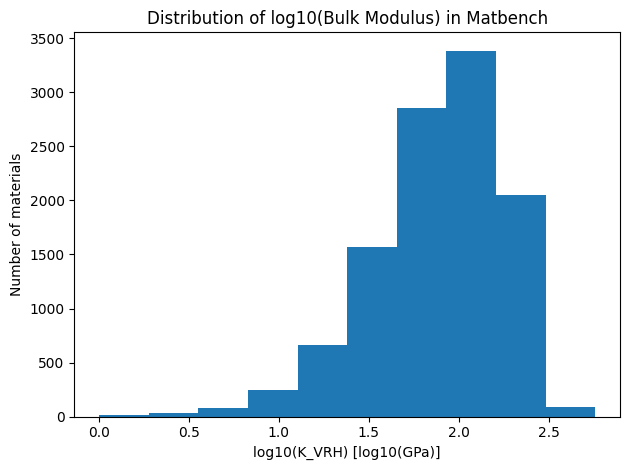

In [12]:
import matplotlib.pyplot as plt

df[target].plot(kind="hist", bins=10)
plt.xlabel("log10(K_VRH) [log10(GPa)]")
plt.ylabel("Number of materials")
plt.title("Distribution of log10(Bulk Modulus) in Matbench")
plt.tight_layout()
plt.show()

In [13]:
df['bulk modulus in GPa'] = 10**df[target]

df['bulk modulus in GPa'].describe()

,bulk modulus in GPa
count,10987.000000
mean,100.853645
std,68.143903
min,1.000000
25%,47.000000
50%,86.000000
75%,144.000000
max,575.000000


In [14]:
structure_column = "structure"

print(df[structure_column].iloc[0])

Full Formula (Ca1 Ag2 Ge2)
Reduced Formula: Ca(AgGe)2
abc   :   4.377179   4.377179   6.313292
angles: 110.283388 110.283388  90.000000
pbc   :       True       True       True
Sites (5)
  #  SP           a         b         c    magmom
---  ----  --------  --------  --------  --------
  0  Ca    0         0         0                0
  1  Ge    0.389492  0.389492  0.778984         0
  2  Ge    0.610508  0.610508  0.221016         0
  3  Ag    0.75      0.25      0.5              0
  4  Ag    0.25      0.75      0.5              0


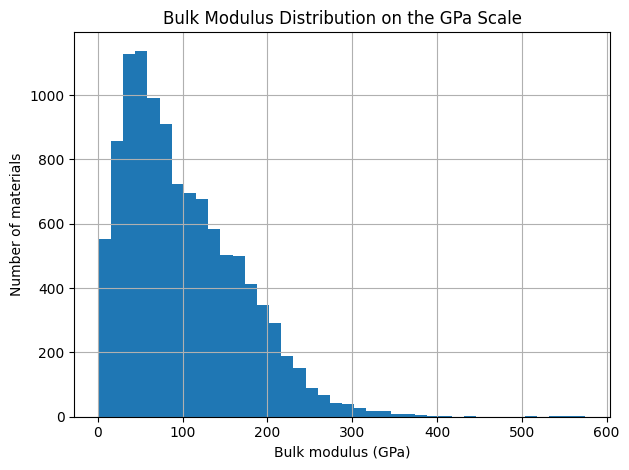

In [15]:
df["bulk modulus in GPa"].hist(bins=40)
plt.xlabel("Bulk modulus (GPa)")
plt.ylabel("Number of materials")
plt.title("Bulk Modulus Distribution on the GPa Scale")
plt.tight_layout()
plt.show()

In [16]:
print('Lowest Bulk Modulus value:')
print(df['bulk modulus in GPa'].nsmallest(5))

print('\nHighest Bulk Modulus value:')
print(df['bulk modulus in GPa'].nlargest(5))

Lowest Bulk Modulus value:
1149    1.0
1163    1.0
2116    1.0
2186    1.0
3851    1.0
Name: bulk modulus in GPa, dtype: float64

Highest Bulk Modulus value:
10770    575.0
2220     551.0
8925     545.0
4365     513.0
10877    436.0
Name: bulk modulus in GPa, dtype: float64


In [17]:
print('Missing values in each column:')
print(df.isnull().sum())

Missing values in each column:
structure              0
log10(K_VRH)           0
bulk modulus in GPa    0
dtype: int64


In [18]:
print("Number of records ", len(df))

print("Median of the Bulk Modulus is ",
      df['bulk modulus in GPa'].median())

print("Mean of the Bulk Modulus is ",
      df['bulk modulus in GPa'].mean())

print("Minimum Bulk Modulus is ",
      df['bulk modulus in GPa'].min())

print("Maximum Bulk Modulus is ",
      df['bulk modulus in GPa'].max())


Number of records  10987
Median of the Bulk Modulus is  85.99999999999999
Mean of the Bulk Modulus is  100.85364521707473
Minimum Bulk Modulus is  1.0
Maximum Bulk Modulus is  575.0000000000001


In [19]:
print("Dataset shape is: ", df.shape)
print("Dataset columns are: ", df.columns.tolist())

Dataset shape is:  (10987, 3)
Dataset columns are:  ['structure', 'log10(K_VRH)', 'bulk modulus in GPa']


## 3. Feature engineering

In [20]:
!pip -q install scikit-learn

In [21]:
from matminer.featurizers.structure import DensityFeatures

In [22]:
from matminer.featurizers.composition import ElementProperty

In [23]:
from pymatgen.core import Composition

In [24]:
model_df = df.copy()

print("Original dataset shape ", df.shape)
print("Modeling dataset shape ", model_df.shape)

Original dataset shape  (10987, 3)
Modeling dataset shape  (10987, 3)


In [25]:
density_features = DensityFeatures()
model_df = density_features.featurize_dataframe(
    model_df,
    col_id ="structure",
    ignore_errors = True
    )
print("Model_df shape after feature generation ", model_df.shape)

DensityFeatures:   0%|          | 0/10987 [00:00<?, ?it/s]

Model_df shape after feature generation  (10987, 6)


In [26]:
model_df.head()

,structure,log10(K_VRH),bulk modulus in GPa,density,vpa,packing fraction
0,"[[0. 0. 0.] Ca, [1.37728887 1.57871271 3.73949...",1.707570,51.0,6.317495,21.085350,0.712400
1,"[[3.14048493 1.09300401 1.64101398] Mg, [0.625...",1.633468,43.0,4.339424,25.348929,0.680633
2,"[[ 2.06884519 2.40627241 -0.45891585] Si, [1....",1.908485,81.0,5.149289,17.470832,0.747221
3,"[[2.06428082 0. 2.06428082] Pd, [0. ...",2.117271,131.0,11.367986,17.592855,0.809013
4,"[[3.09635262 1.0689416 1.53602403] Mg, [0.593...",1.690196,49.0,3.337111,24.094482,0.672807


In [27]:
model_df["composition"] = model_df["structure"].apply(
    lambda structure: structure.composition
)

model_df[["structure","composition"]].head()

,structure,composition
0,"[[0. 0. 0.] Ca, [1.37728887 1.57871271 3.73949...","(Ca, Ge, Ag)"
1,"[[3.14048493 1.09300401 1.64101398] Mg, [0.625...","(Mg, Ge, Ba)"
2,"[[ 2.06884519 2.40627241 -0.45891585] Si, [1....","(Si, Cu, Sr)"
3,"[[2.06428082 0. 2.06428082] Pd, [0. ...","(Pd, Dy)"
4,"[[3.09635262 1.0689416 1.53602403] Mg, [0.593...","(Mg, Si, Ba)"


## 4. Prepare features and target

In [28]:
composition_featurizer = ElementProperty.from_preset("magpie")

model_df = composition_featurizer.featurize_dataframe(
    model_df,
    col_id = "composition",
    ignore_errors =True
)

print("Model_df shape after composition feature generation ", model_df.shape)

ElementProperty:   0%|          | 0/10987 [00:00<?, ?it/s]

Model_df shape after composition feature generation  (10987, 139)


In [29]:
target = "log10(K_VRH)"

excluded_columns = [
    "structure",
    "composition",
    target,
    "bulk modulus in GPa"
]

features_df = model_df.drop(
    columns = excluded_columns,
    errors ="ignore"
)

features_df = features_df.select_dtypes(include = "number")

print("Number of candidate features ", features_df.shape[1])
print("Feature names: ")
print(features_df.columns.tolist())

Number of candidate features  135
Feature names: 
['density', 'vpa', 'packing fraction', 'MagpieData minimum Number', 'MagpieData maximum Number', 'MagpieData range Number', 'MagpieData mean Number', 'MagpieData avg_dev Number', 'MagpieData mode Number', 'MagpieData minimum MendeleevNumber', 'MagpieData maximum MendeleevNumber', 'MagpieData range MendeleevNumber', 'MagpieData mean MendeleevNumber', 'MagpieData avg_dev MendeleevNumber', 'MagpieData mode MendeleevNumber', 'MagpieData minimum AtomicWeight', 'MagpieData maximum AtomicWeight', 'MagpieData range AtomicWeight', 'MagpieData mean AtomicWeight', 'MagpieData avg_dev AtomicWeight', 'MagpieData mode AtomicWeight', 'MagpieData minimum MeltingT', 'MagpieData maximum MeltingT', 'MagpieData range MeltingT', 'MagpieData mean MeltingT', 'MagpieData avg_dev MeltingT', 'MagpieData mode MeltingT', 'MagpieData minimum Column', 'MagpieData maximum Column', 'MagpieData range Column', 'MagpieData mean Column', 'MagpieData avg_dev Column', 'Magp

In [30]:
y = model_df[target]

print("Number of target observations ", len(y))
print(y.head())


Number of target observations  10987
0    1.707570
1    1.633468
2    1.908485
3    2.117271
4    1.690196
Name: log10(K_VRH), dtype: float64


In [31]:
print("Missing values in target ", y.isnull().sum())

missing_features = features_df.isnull().sum()

print("Features missing values:")
print(missing_features[missing_features > 0])


Missing values in target  0
Features missing values:
Series([], dtype: int64)


## 5. Train regression models

In [32]:
from sklearn.model_selection import train_test_split

valid_target = y.notna()

X = features_df.loc[valid_target].copy()
y = y.loc[valid_target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42
)

print("Training record: ", len(X_train), "records")
print("Testing records: ", len(X_test), "records")


Training record:  8789 records
Testing records:  2198 records


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

In [34]:
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_prediction = linear_model.predict(X_test)

print("First five Linear Predictions are:")
print(linear_prediction[:5])

First five Linear Predictions are:
[1.57018132 1.81616204 2.29459764 1.41043576 2.18054614]


In [35]:
from sklearn.ensemble import RandomForestRegressor


In [36]:
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy ="median")),
    ("model", RandomForestRegressor(
        n_estimators = 100,
        random_state = 42,
        n_jobs = -1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_prediction = random_forest_model.predict(X_test)

print("First five Random Forest Predictions: ")
print(rf_prediction[:5])

First five Random Forest Predictions: 
[1.5059497  1.81863422 2.27134489 1.40900461 2.26172018]


In [37]:
print("Number of test record ", len(y_test))
print("Number of Linear prediction records ", len(linear_prediction))
print("Number of Random Forest prediction Records ", len(rf_prediction))

Number of test record  2198
Number of Linear prediction records  2198
Number of Random Forest prediction Records  2198


In [38]:
import joblib

joblib.dump(linear_model, "Linear Regression Model pk1")
joblib.dump(random_forest_model, "Random Forest Regression Model pk1")

print("Both models have been saved successfully")

Both models have been saved successfully


## 6. Evaluate model performance

## Methodology summary

1. Load the Matbench `matbench_log_kvrh` dataset.
2. Generate structure-derived density descriptors with Matminer's `DensityFeatures` and composition-based elemental descriptors with `ElementProperty.from_preset("magpie")`.
3. Use `log10(K_VRH)` as the prediction target and exclude the structure, composition, target, and derived GPa-scale target from the input features.
4. Split the data randomly into 80% training data and 20% test data (`random_state=42`).
5. Fit a Linear Regression baseline and a Random Forest regressor with 100 trees (`random_state=42`).
6. Evaluate both models using MAE, RMSE, and R². Median imputation is included in the pipelines; standardization is applied to Linear Regression.

The reported scores come from this project's own random train/test split. They are not official Matbench leaderboard results.

In [39]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [40]:
def evaluate_model(name, y_true, y_pred):

  mae = mean_absolute_error(y_true, y_pred)

  rmse = np.sqrt(mean_squared_error(y_true, y_pred))

  r2 = r2_score(y_true, y_pred)

  return{
      "Model": name,
      "MAE": mae,
      "RMSE": rmse,
      "R2": r2
  }

In [41]:
linear_results = evaluate_model (
    "Linear Regression",
    y_test,
    linear_prediction
)

print(linear_results)

{'Model': 'Linear Regression', 'MAE': 0.09849494823107659, 'RMSE': np.float64(0.15417955671343567), 'R2': 0.8342905201491165}


In [42]:
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    rf_prediction
)

print(rf_results)

{'Model': 'Random Forest', 'MAE': 0.07081246140354033, 'RMSE': np.float64(0.12386427809178999), 'R2': 0.893048736304495}


## 7. Inspect Random Forest feature importance

In [43]:
import pandas as pd

results_df = pd.DataFrame([linear_results, rf_results])
results_df = results_df.round(4)
print(results_df)

               Model     MAE    RMSE      R2
0  Linear Regression  0.0985  0.1542  0.8343
1      Random Forest  0.0708  0.1239  0.8930


### Model-performance figures
The following figures are generated from `results_df`, which is calculated from the predictions produced by the models above. This keeps the report figures reproducible from the notebook. MAE and RMSE are on the `log10(K_VRH)` target scale.

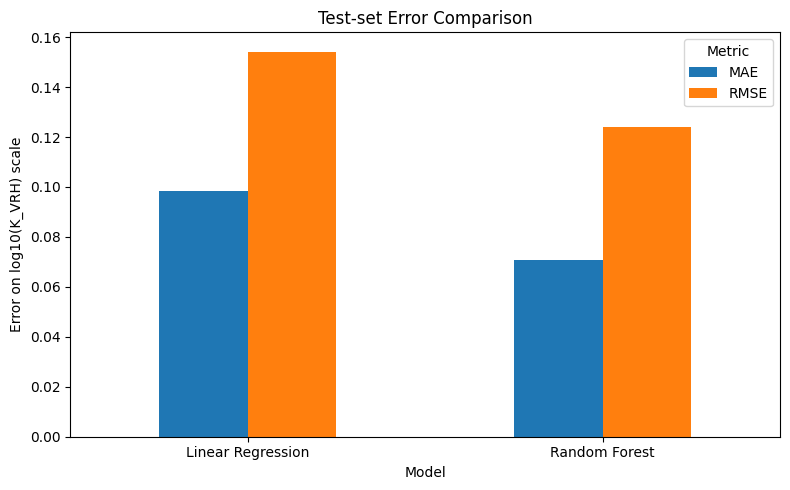

In [44]:
# Figure: compare MAE and RMSE using the evaluated test-set results
metric_plot_df = results_df.set_index('Model')[['MAE', 'RMSE']]
ax = metric_plot_df.plot(kind='bar', figsize=(8, 5))
ax.set_title('Test-set Error Comparison')
ax.set_xlabel('Model')
ax.set_ylabel('Error on log10(K_VRH) scale')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Metric')
plt.tight_layout()
plt.show()

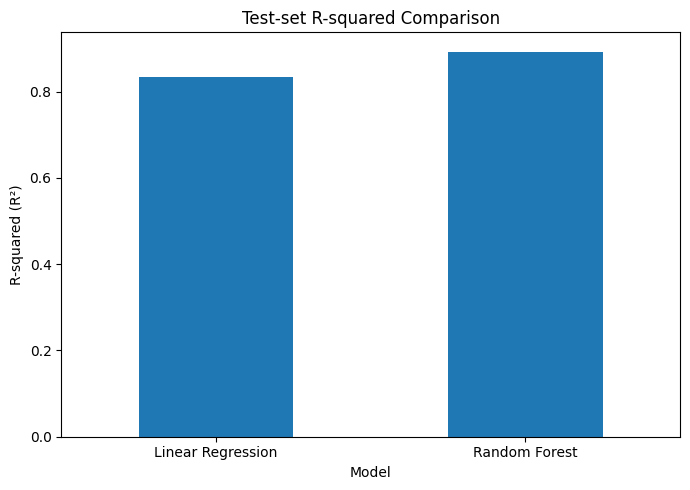

In [45]:
# Figure: compare R-squared using the evaluated test-set results
ax = results_df.set_index('Model')['R2'].plot(kind='bar', figsize=(7, 5))
ax.set_title('Test-set R-squared Comparison')
ax.set_xlabel('Model')
ax.set_ylabel('R-squared (R²)')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Model-performance figures
The following figures are generated from `results_df`, which is calculated from the predictions produced by the models above. This keeps the report figures reproducible from the notebook. MAE and RMSE are on the `log10(K_VRH)` target scale.

In [46]:
rf_estimator = random_forest_model.named_steps["model"]

print(type(rf_estimator))

<class 'sklearn.ensemble._forest.RandomForestRegressor'>


In [47]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by = "Importance",
    ascending = False
)

print(importance_df.head(10).round(4))

                                Feature  Importance
1                                   vpa      0.4178
24             MagpieData mean MeltingT      0.1468
60            MagpieData mean NpValence      0.0604
0                               density      0.0544
2                      packing fraction      0.0380
108           MagpieData mean NUnfilled      0.0301
10   MagpieData maximum MendeleevNumber      0.0218
36                  MagpieData mean Row      0.0167
48    MagpieData mean Electronegativity      0.0108
112      MagpieData maximum GSvolume_pa      0.0101


## 8. Visualize predictions

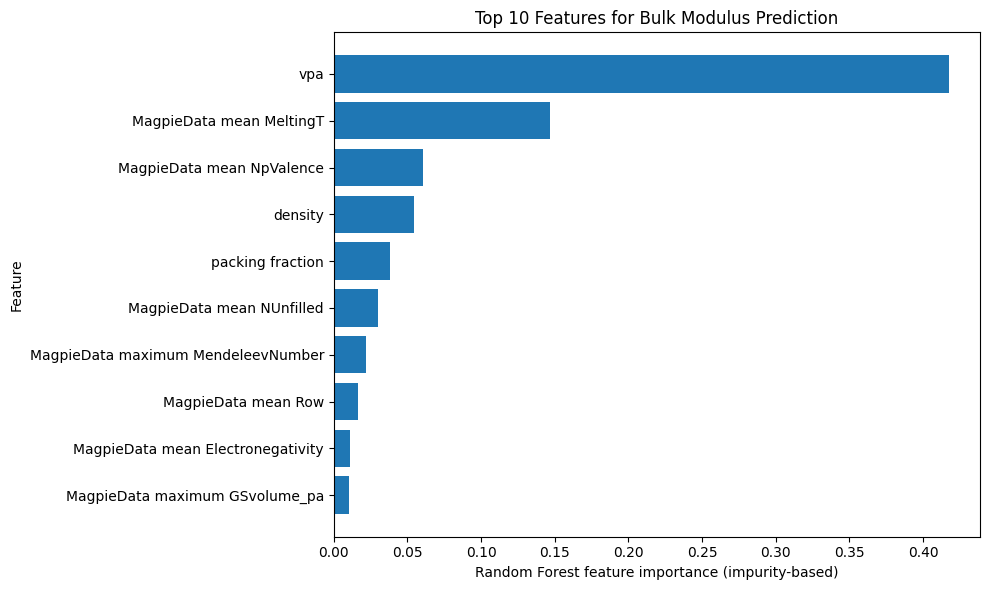

In [48]:
import matplotlib.pyplot as plt

top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Random Forest feature importance (impurity-based)")
plt.ylabel("Feature")
plt.title("Top 10 Features for Bulk Modulus Prediction")
plt.tight_layout()
plt.show()

## 9. Export results

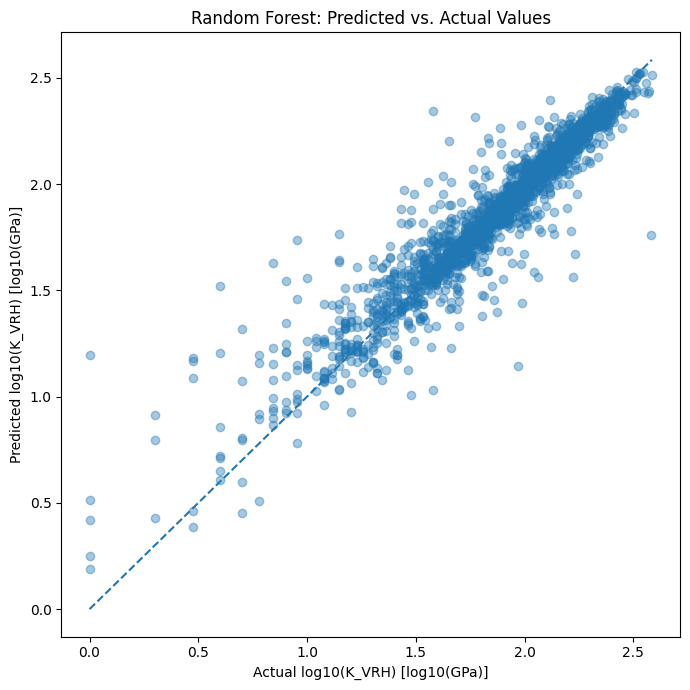

In [49]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, rf_prediction, alpha=0.4)

minimum = min(y_test.min(), rf_prediction.min())
maximum = max(y_test.max(), rf_prediction.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")

plt.xlabel("Actual log10(K_VRH) [log10(GPa)]")
plt.ylabel("Predicted log10(K_VRH) [log10(GPa)]")
plt.title("Random Forest: Predicted vs. Actual Values")
plt.tight_layout()
plt.show()

In [50]:
results_df.to_csv("Model performance.csv", index = False)
importance_df.to_csv("Random Forest feature importance.csv", index = False)

print("Performance and Feature tables saved")

Performance and Feature tables saved


## Model comparison

| Metric | Linear Regression | Random Forest |
|---|---:|---:|
| MAE | 0.0985 | 0.0708 |
| RMSE | 0.1542 | 0.1239 |
| R² | 0.8343 | 0.8930 |

MAE and RMSE are measured on the `log10(K_VRH)` target scale, not directly in GPa. Higher R² indicates that the model explains a larger proportion of the variation in the held-out test targets.

## Interpretation and limitations

### Model comparison
Random Forest performed better than Linear Regression on all three reported test metrics. Its MAE decreased from 0.0985 to 0.0708, its RMSE decreased from 0.1542 to 0.1239, and its R² increased from 0.8343 to 0.8930. These results indicate stronger predictive performance on this particular random test split.

### Feature importance
The ten highest-ranked features from the notebook's Random Forest model were:

| Rank | Feature | Importance |
|---:|---|---:|
| 1 | `vpa` | 0.4178 |
| 2 | `MagpieData mean MeltingT` | 0.1468 |
| 3 | `MagpieData mean NpValence` | 0.0604 |
| 4 | `density` | 0.0544 |
| 5 | `packing fraction` | 0.0380 |
| 6 | `MagpieData mean NUnfilled` | 0.0301 |
| 7 | `MagpieData maximum MendeleevNumber` | 0.0218 |
| 8 | `MagpieData mean Row` | 0.0167 |
| 9 | `MagpieData mean Electronegativity` | 0.0108 |
| 10 | `MagpieData maximum GSvolume_pa` | 0.0101 |

`vpa` (volume per atom) had the highest importance score. The results suggest that volume-related structural information and selected elemental descriptors were useful to the trained model. These are predictive associations, not evidence that a feature causes changes in bulk modulus. Correlated features can also affect impurity-based Random Forest importance.

### Limitations
- The target values are computationally derived in the Matbench dataset, rather than direct experimental measurements.
- A random train/test split can place chemically or structurally similar materials in both sets, so these results do not by themselves establish performance on entirely new material families.
- Only two regression models were compared, and the project did not include extensive hyperparameter tuning or external validation.
- Bulk modulus is only one material property and cannot alone determine suitability for demanding engineering environments.
- Feature importance is model-dependent and should not be interpreted causally.

## Final data and split checks

In [51]:
print("Original dataset shape:", df.shape)
print("Modeling dataset shape:", model_df.shape)
print("Number of input features:", X_train.shape[1])
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Original dataset shape: (10987, 3)
Modeling dataset shape: (10987, 139)
Number of input features: 135
Training records: 8789
Testing records: 2198


## Missing-value checks

In [52]:
print("Missing target values:", y.isnull().sum())
print("Missing feature values in X_train:", X_train.isnull().sum().sum())
print("Missing feature values in X_test:", X_test.isnull().sum().sum())

Missing target values: 0
Missing feature values in X_train: 0
Missing feature values in X_test: 0
